# Task 28 - Hyperparameter Tuning: GridSearchCV, RandomizedSearchCV and Bayesian Optimization

**Goal:** tune hyperparameters with automated search (grid, random, Bayesian) and make sure the tuned model **generalizes** (hold-out set, nested CV, learning and validation curves).

**Target:** `log_revenue = log1p(price x units_sold)` from Task 25 (there is no `yearly amount spent` column; see Task 25). Features: the Task 25 pool (leakage-safe).

**Design**
1. **Fair search comparison:** one model (`HistGradientBoostingRegressor`) tuned by all three methods with a comparable budget; compared on best CV RMSE, hold-out RMSE, evaluations and time, plus convergence curves.
2. **Model-family comparison:** Elastic Net (grid), Random Forest (randomized search), HistGradientBoosting (best of step 1), against untuned defaults.
3. **Generalization checks:** untouched 20% hold-out, **nested CV** (inner search, outer scoring), learning curve, validation curve, CV-vs-hold-out gap.
Bayesian optimization uses **Optuna (TPE sampler)**; `pip install optuna`.

**Input:** `data/processed/womens_clothing_regression_dataset.csv` + `reports/task_25_selected_features.csv` (run Task 25 first)
**Outputs:** `data/processed/womens_clothing_tuned_regression_predictions.csv` (all predictions are out-of-sample: CV for train rows, hold-out for test rows), `reports/task_28_search_comparison.csv`, `task_28_model_comparison.csv`, `task_28_best_params.csv`, `task_28_search_history.csv`, `task_28_generalization.csv`, `task_28_analysis_status.csv`

In [1]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
RAW = ROOT / "data" / "raw" / "womens_clothing.csv"
PROC.mkdir(parents=True, exist_ok=True); REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths):
    """Load the first existing CSV, so each task builds on the newest previous output."""
    for p in paths:
        if Path(p).exists():
            d = pd.read_csv(p)
            d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
            print(f"Loaded: {Path(p).name}  shape={d.shape}")
            return d, Path(p)
    raise FileNotFoundError("None of these files exist: " + ", ".join(str(p) for p in paths))

def add_from_raw(df, *names):
    """Borrow columns missing from df (e.g. title, tags) from data/raw, matched on product_id."""
    missing = [n for n in names if pick(df, n, required=False) is None]
    if not missing:
        return df
    raw = pd.read_csv(RAW); raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]
    kd, kr = pick(df, "product_id", required=False), pick(raw, "product_id", required=False)
    if kd is None or kr is None:
        raise KeyError(f"Need product_id in both files to borrow {missing} from raw")
    got = [pick(raw, n) for n in missing if pick(raw, n, required=False)]
    if not got:
        raise KeyError(f"{missing} not found in raw file either")
    add = raw.drop_duplicates(kr)[[kr] + got].rename(columns={kr: kd})
    out = df.merge(add, on=kd, how="left")
    print("Borrowed from raw:", got)
    return out

# Newest cumulative dataset first; each task reads the newest file produced BEFORE it.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

# Tasks 19-21 outputs sit in front of the older chain.
LATE = ["womens_clothing_lifecycle_features.csv", "womens_clothing_tfidf_features.csv", "womens_clothing_channel_interaction_features.csv"]
FULL = LATE + CHAIN

# Tasks 22-24 outputs sit in front of everything.
LATE2 = ["womens_clothing_rating_sentiment_encoded.csv", "womens_clothing_pca_features.csv"]
ALL = LATE2 + FULL

REG_DATASET = "womens_clothing_regression_dataset.csv"      # written by Task 25, read by Tasks 26-27

import time
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score, cross_val_predict,
                                     learning_curve, validation_curve)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
try:
    import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING); HAS_OPTUNA = True
except ImportError:
    HAS_OPTUNA = False; print("optuna not installed -> Bayesian search will be skipped (pip install optuna)")
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42; TARGET_NAME = "log_revenue"
FEATURE_SET = "pool"            # "pool" (all Task 25 pool features) or "selected"
N_ITER = 30                     # budget for random search and Bayesian trials
RUN_NESTED = True

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


## 1. Load data and create the validation split

In [2]:
reg = pd.read_csv(PROC / "womens_clothing_regression_dataset.csv"); ft = pd.read_csv(REPORTS / "task_25_selected_features.csv")
id_col = pick(reg, "product_id", required=False); y = reg[TARGET_NAME]
features = list(ft.loc[ft["type"] == "pool", "feature"]) if FEATURE_SET == "pool" else list(ft.loc[ft["selected"] | ft["interaction_kept"], "feature"])
X = reg[features]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
def rmse(a, b): return mean_squared_error(a, b) ** .5
print(f"{len(X):,} rows | {X.shape[1]} features | train {len(Xtr):,} / hold-out {len(Xte):,} (hold-out is never used for tuning)")
base = {"ElasticNet": make_pipeline(StandardScaler(), ElasticNet(alpha=1.0)), "RandomForest": RandomForestRegressor(200, random_state=RANDOM_STATE, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE)}
defaults = []
for n, m in base.items():
    s = -cross_val_score(m, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    defaults.append({"model": n, "tuning": "defaults", "cv_rmse": s.mean(), "cv_rmse_sd": s.std(), "holdout_rmse": rmse(yte, m.fit(Xtr, ytr).predict(Xte))})
pd.DataFrame(defaults).round(4)

1,539 rows | 88 features | train 1,231 / hold-out 308 (hold-out is never used for tuning)


,model,tuning,cv_rmse,cv_rmse_sd,holdout_rmse
0,ElasticNet,defaults,2.1309,0.0283,2.0850
1,RandomForest,defaults,1.5381,0.0265,1.5132
2,HistGradientBoosting,defaults,1.4908,0.0307,1.5371


## 2. Search-method comparison on HistGradientBoosting

Same model, same 5-fold CV, three strategies:
- **GridSearchCV:** every combination of a small discrete grid (exhaustive, cheap only for few parameters)
- **RandomizedSearchCV:** `N_ITER` random draws from wide distributions
- **Bayesian (Optuna TPE):** `N_ITER` trials that learn from earlier trials where to sample next

In [3]:
hgb_base = dict(random_state=RANDOM_STATE, max_iter=150)
history = []                                                     # (method, evaluation_no, cv_rmse)
results = []

# --- Grid ---
grid = {"learning_rate": [0.03, 0.1], "max_depth": [3, 6], "min_samples_leaf": [10, 30], "l2_regularization": [0.0, 1.0]}
t0 = time.time(); gs = GridSearchCV(HistGradientBoostingRegressor(**hgb_base), grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(Xtr, ytr); t_grid = time.time() - t0
history += [("Grid", i + 1, -s) for i, s in enumerate(gs.cv_results_["mean_test_score"])]
results.append({"method": "GridSearchCV", "evaluations": len(gs.cv_results_["params"]), "seconds": t_grid, "best_cv_rmse": -gs.best_score_, "best_params": gs.best_params_, "estimator": gs.best_estimator_})

# --- Random ---
dist = {"learning_rate": loguniform(0.01, 0.3), "max_depth": randint(2, 10), "min_samples_leaf": randint(5, 80), "l2_regularization": loguniform(1e-3, 10),
        "max_leaf_nodes": randint(8, 64), "max_features": uniform(0.3, 0.7)}
t0 = time.time(); rs = RandomizedSearchCV(HistGradientBoostingRegressor(**hgb_base), dist, n_iter=N_ITER, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr); t_rand = time.time() - t0
history += [("Random", i + 1, -s) for i, s in enumerate(rs.cv_results_["mean_test_score"])]
results.append({"method": "RandomizedSearchCV", "evaluations": N_ITER, "seconds": t_rand, "best_cv_rmse": -rs.best_score_, "best_params": rs.best_params_, "estimator": rs.best_estimator_})

# --- Bayesian (Optuna) ---
study = None
if HAS_OPTUNA:
    def objective(trial):
        p = {"learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True), "max_depth": trial.suggest_int("max_depth", 2, 9),
             "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 80), "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
             "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 63), "max_features": trial.suggest_float("max_features", 0.3, 1.0)}
        return -cross_val_score(HistGradientBoostingRegressor(**hgb_base, **p), Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    t0 = time.time(); study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)); study.optimize(objective, n_trials=N_ITER); t_bayes = time.time() - t0
    history += [("Bayesian (TPE)", t.number + 1, t.value) for t in study.trials]
    results.append({"method": "Bayesian (Optuna TPE)", "evaluations": N_ITER, "seconds": t_bayes, "best_cv_rmse": study.best_value, "best_params": study.best_params,
                    "estimator": HistGradientBoostingRegressor(**hgb_base, **study.best_params).fit(Xtr, ytr)})
for r in results:
    est = r["estimator"]; est.fit(Xtr, ytr) if not hasattr(est, "n_iter_") else None
    r["holdout_rmse"] = rmse(yte, est.predict(Xte)); r["holdout_mae"] = mean_absolute_error(yte, est.predict(Xte)); r["holdout_r2"] = r2_score(yte, est.predict(Xte))
    r["cv_to_holdout_gap"] = r["holdout_rmse"] - r["best_cv_rmse"]
search_cmp = pd.DataFrame([{k: v for k, v in r.items() if k != "estimator"} for r in results]); search_cmp["best_params"] = search_cmp["best_params"].astype(str); search_cmp.round(4)

,method,evaluations,seconds,best_cv_rmse,best_params,holdout_rmse,holdout_mae,holdout_r2,cv_to_holdout_gap
0,GridSearchCV,16,17.0984,1.4962,"{'l2_regularization': 1.0, 'learning_rate': 0....",1.5413,1.2160,0.4852,0.0451
1,RandomizedSearchCV,30,30.8223,1.5053,{'l2_regularization': np.float64(3.82872683931...,1.5147,1.2180,0.5028,0.0095
2,Bayesian (Optuna TPE),30,59.4182,1.4774,"{'learning_rate': 0.041359901534120634, 'max_d...",1.4832,1.1764,0.5233,0.0058


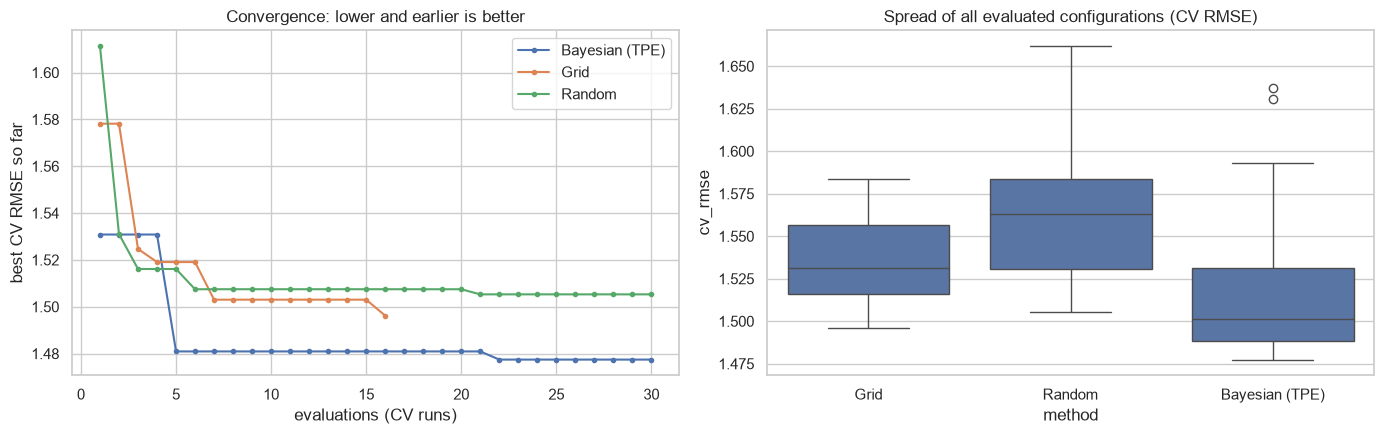

In [4]:
hist = pd.DataFrame(history, columns=["method", "evaluation", "cv_rmse"]); hist["best_so_far"] = hist.groupby("method")["cv_rmse"].cummin()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for m, g in hist.groupby("method"): ax[0].plot(g["evaluation"], g["best_so_far"], marker="o", ms=3, label=m)
ax[0].set_xlabel("evaluations (CV runs)"); ax[0].set_ylabel("best CV RMSE so far"); ax[0].set_title("Convergence: lower and earlier is better"); ax[0].legend()
sns.boxplot(data=hist, x="method", y="cv_rmse", ax=ax[1], color="#4c72b0"); ax[1].set_title("Spread of all evaluated configurations (CV RMSE)"); plt.tight_layout(); plt.show()

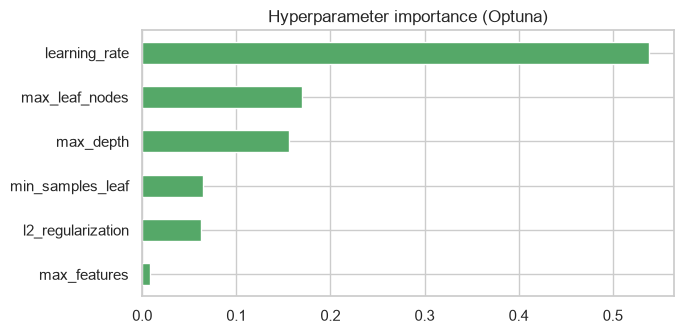

In [5]:
if study is not None and len(study.trials) >= 10:
    try:
        imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values(); imp.plot.barh(figsize=(7, 3.5), color="#55a868"); plt.title("Hyperparameter importance (Optuna)"); plt.tight_layout(); plt.show()
    except Exception as e: print("importance unavailable:", str(e)[:80])

## 3. Model-family comparison (each tuned with its most suitable search)

- **Elastic Net** (small continuous space) -> GridSearchCV
- **Random Forest** (many discrete parameters) -> RandomizedSearchCV
- **HistGradientBoosting** -> best of the three searches above

In [6]:
fam = []
t0 = time.time(); g2 = GridSearchCV(make_pipeline(StandardScaler(), ElasticNet(max_iter=20000)), {"elasticnet__alpha": np.logspace(-3, 0, 7), "elasticnet__l1_ratio": [.1, .5, .9]}, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(Xtr, ytr)
fam.append({"model": "ElasticNet", "search": "GridSearchCV", "evaluations": len(g2.cv_results_["params"]), "seconds": time.time() - t0, "cv_rmse": -g2.best_score_, "best_params": g2.best_params_, "estimator": g2.best_estimator_})
t0 = time.time(); r2_ = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1), {"n_estimators": randint(100, 400), "max_depth": randint(3, 20), "min_samples_leaf": randint(1, 20), "max_features": uniform(0.2, 0.8)},
                                            n_iter=N_ITER, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr)
fam.append({"model": "RandomForest", "search": "RandomizedSearchCV", "evaluations": N_ITER, "seconds": time.time() - t0, "cv_rmse": -r2_.best_score_, "best_params": r2_.best_params_, "estimator": r2_.best_estimator_})
best_hgb = min(results, key=lambda r: r["best_cv_rmse"])
fam.append({"model": "HistGradientBoosting", "search": best_hgb["method"], "evaluations": best_hgb["evaluations"], "seconds": best_hgb["seconds"], "cv_rmse": best_hgb["best_cv_rmse"], "best_params": best_hgb["best_params"], "estimator": best_hgb["estimator"]})
for f in fam:
    p = f["estimator"].predict(Xte); f["holdout_rmse"], f["holdout_mae"], f["holdout_r2"] = rmse(yte, p), mean_absolute_error(yte, p), r2_score(yte, p)
dflt = pd.DataFrame(defaults).set_index("model")
model_cmp = pd.DataFrame([{k: v for k, v in f.items() if k != "estimator"} for f in fam]); model_cmp["default_holdout_rmse"] = model_cmp["model"].map(dflt["holdout_rmse"])
model_cmp["gain_vs_default"] = model_cmp["default_holdout_rmse"] - model_cmp["holdout_rmse"]; model_cmp["best_params"] = model_cmp["best_params"].astype(str)
model_cmp.round(4)

,model,search,evaluations,seconds,cv_rmse,best_params,holdout_rmse,holdout_mae,holdout_r2,default_holdout_rmse,gain_vs_default
0,ElasticNet,GridSearchCV,21,1.0925,1.8374,"{'elasticnet__alpha': np.float64(0.1), 'elasti...",1.7739,1.4470,0.3182,2.0850,0.3111
1,RandomForest,RandomizedSearchCV,30,95.0400,1.5331,"{'max_depth': 14, 'max_features': np.float64(0...",1.5120,1.2234,0.5046,1.5132,0.0012
2,HistGradientBoosting,Bayesian (Optuna TPE),30,59.4182,1.4774,"{'learning_rate': 0.041359901534120634, 'max_d...",1.4832,1.1764,0.5233,1.5371,0.0538


## 4. Pick the model and test generalization

The winner is the model with the lowest CV RMSE (1-SE rule not needed here because the hold-out is a separate check). Then:
- **Hold-out** performance (never used for tuning)
- **Nested CV**: the inner loop repeats the search inside every outer training fold, giving an unbiased estimate of "tune + fit" performance
- **Learning curve** (do more rows help?) and **validation curve** for the most important parameter

In [7]:
champ = min(fam, key=lambda f: f["cv_rmse"]); est = champ["estimator"]
p_te = est.predict(Xte)
gen = {"champion": champ["model"], "search": champ["search"], "cv_rmse_train": champ["cv_rmse"], "holdout_rmse": rmse(yte, p_te), "holdout_mae": mean_absolute_error(yte, p_te), "holdout_r2": r2_score(yte, p_te)}
gen["cv_to_holdout_gap"] = gen["holdout_rmse"] - gen["cv_rmse_train"]
gen["train_rmse"] = rmse(ytr, est.predict(Xtr))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in gen.items()})

{'champion': 'HistGradientBoosting', 'search': 'Bayesian (Optuna TPE)', 'cv_rmse_train': 1.4774, 'holdout_rmse': 1.4832, 'holdout_mae': 1.1764, 'holdout_r2': 0.5233, 'cv_to_holdout_gap': 0.0058, 'train_rmse': 0.3915}


In [8]:
if RUN_NESTED:
    outer = KFold(5, shuffle=True, random_state=RANDOM_STATE + 1); nested = []
    space = {"HistGradientBoosting": (HistGradientBoostingRegressor(**hgb_base), dist), "RandomForest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1), r2_.param_distributions)}
    mk = space.get(champ["model"])
    for tr, te in outer.split(X):
        if mk is None: inner = GridSearchCV(make_pipeline(StandardScaler(), ElasticNet(max_iter=20000)), {"elasticnet__alpha": np.logspace(-3, 0, 7), "elasticnet__l1_ratio": [.1, .5, .9]}, cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
        else: inner = RandomizedSearchCV(mk[0], mk[1], n_iter=max(8, N_ITER // 3), cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=RANDOM_STATE)
        inner.fit(X.iloc[tr], y.iloc[tr]); nested.append(rmse(y.iloc[te], inner.predict(X.iloc[te])))
    gen["nested_cv_rmse_mean"], gen["nested_cv_rmse_sd"] = float(np.mean(nested)), float(np.std(nested))
    print(f"Nested CV RMSE (outer 5-fold, inner search): {np.mean(nested):.4f} +- {np.std(nested):.4f}  vs  tuned CV RMSE {champ['cv_rmse']:.4f}  vs  hold-out {gen['holdout_rmse']:.4f}")

Nested CV RMSE (outer 5-fold, inner search): 1.4990 +- 0.0533  vs  tuned CV RMSE 1.4774  vs  hold-out 1.4832


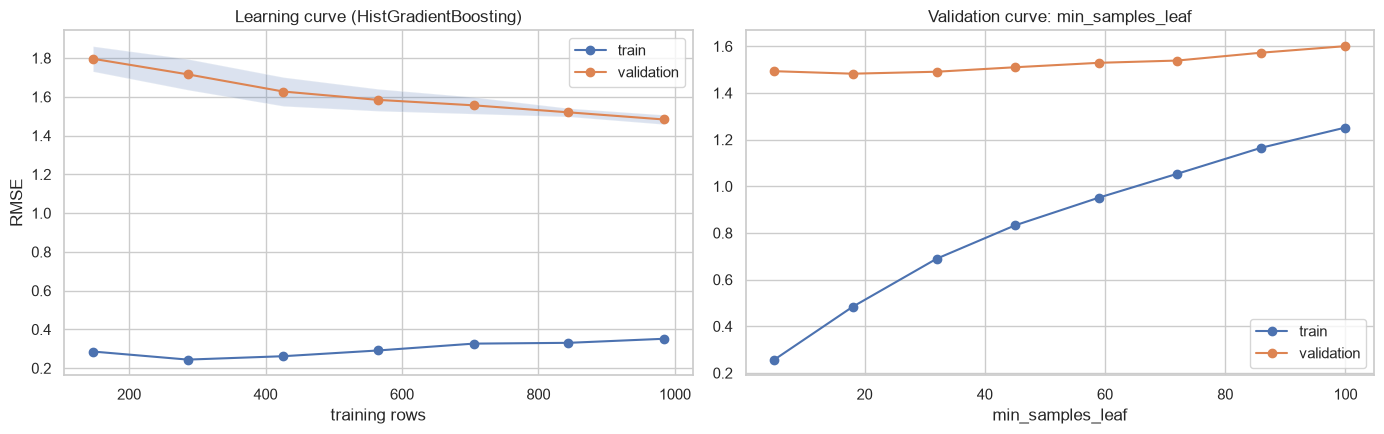

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sizes, tr_s, te_s = learning_curve(est, Xtr, ytr, train_sizes=np.linspace(.15, 1, 7), cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
ax[0].plot(sizes, -tr_s.mean(1), marker="o", label="train"); ax[0].plot(sizes, -te_s.mean(1), marker="o", label="validation"); ax[0].fill_between(sizes, -te_s.mean(1) - te_s.std(1), -te_s.mean(1) + te_s.std(1), alpha=.2)
ax[0].set_xlabel("training rows"); ax[0].set_ylabel("RMSE"); ax[0].set_title(f"Learning curve ({champ['model']})"); ax[0].legend()
vp = {"HistGradientBoosting": ("min_samples_leaf", np.unique(np.linspace(5, 100, 8).astype(int))), "RandomForest": ("min_samples_leaf", np.arange(1, 25, 3)), "ElasticNet": ("elasticnet__alpha", np.logspace(-3, 0.5, 8))}[champ["model"]]
tr_v, te_v = validation_curve(est, Xtr, ytr, param_name=vp[0], param_range=vp[1], cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
ax[1].plot(vp[1], -tr_v.mean(1), marker="o", label="train"); ax[1].plot(vp[1], -te_v.mean(1), marker="o", label="validation"); ax[1].set_xlabel(vp[0]); ax[1].set_title(f"Validation curve: {vp[0]}"); ax[1].legend()
if champ["model"] == "ElasticNet": ax[1].set_xscale("log")
plt.tight_layout(); plt.show()

## 5. Out-of-sample predictions for Task 29

In [10]:
oof = cross_val_predict(est, Xtr, ytr, cv=cv, n_jobs=-1)
pred = pd.Series(np.nan, index=X.index); pred[Xtr.index] = oof; pred[Xte.index] = p_te
out = pd.DataFrame({TARGET_NAME: y, "predicted": pred, "split": np.where(X.index.isin(Xte.index), "holdout", "train_cv_oof")})
if id_col: out.insert(0, id_col, reg[id_col].values)
out["residual"] = out[TARGET_NAME] - out["predicted"]; out["model"] = champ["model"]
print(out.groupby("split")["residual"].agg(["count", "mean", "std"]).round(4))

              count   mean     std
split                             
holdout         308 -0.062  1.4843
train_cv_oof   1231  0.031  1.4780


## 6. Save outputs

In [11]:
out_path = PROC / "womens_clothing_tuned_regression_predictions.csv"; out.to_csv(out_path, index=False)
search_cmp.round(6).to_csv(REPORTS / "task_28_search_comparison.csv", index=False); model_cmp.round(6).to_csv(REPORTS / "task_28_model_comparison.csv", index=False)
pd.DataFrame([{"model": f["model"], "search": f["search"], "param": k, "value": v} for f in fam for k, v in f["best_params"].items()]).to_csv(REPORTS / "task_28_best_params.csv", index=False)
hist.round(6).to_csv(REPORTS / "task_28_search_history.csv", index=False)
pd.DataFrame([gen]).round(6).to_csv(REPORTS / "task_28_generalization.csv", index=False)
status = pd.DataFrame([{"task": "Task 28 - Hyperparameter tuning", "status": "completed", "run_at": datetime.now().isoformat(timespec="seconds"), "rows": len(X), "n_features": X.shape[1], "n_iter_budget": N_ITER,
    "bayesian_available": HAS_OPTUNA, "best_search_method_hgb": best_hgb["method"], "champion_model": champ["model"], "champion_search": champ["search"], "cv_rmse": round(champ["cv_rmse"], 4),
    "holdout_rmse": round(gen["holdout_rmse"], 4), "holdout_r2": round(gen["holdout_r2"], 4), "nested_cv_rmse": round(gen.get("nested_cv_rmse_mean", float("nan")), 4), "output_dataset": out_path.name}])
status.to_csv(REPORTS / "task_28_analysis_status.csv", index=False); status.T

,0
task,Task 28 - Hyperparameter tuning
status,completed
run_at,2026-11-27T16:05:54
rows,1539
n_features,88
n_iter_budget,30
bayesian_available,True
best_search_method_hgb,Bayesian (Optuna TPE)
champion_model,HistGradientBoosting
champion_search,Bayesian (Optuna TPE)
